In [1]:
from datasets import load_dataset

In [2]:
dataset = load_dataset("HuggingFaceM4/FineVisionMax",
                       split="train",
                       streaming=True)

README.md:   0%|          | 0.00/4.25k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/10000 [00:00<?, ?it/s]

In [3]:
print(next(iter(dataset)))

{'images': [<PIL.PngImagePlugin.PngImageFile image mode=RGB size=1506x1102 at 0x7FE347A3EE90>], 'texts': [{'user': 'What is the primary key of the Equipment entity?', 'assistant': 'The primary key of the Equipment entity is EquipmentID, which uniquely identifies each piece of equipment in the diagram.\nAnswer: EquipmentID'}, {'user': 'What is the relationship between Equipment and Maintenance Record?', 'assistant': 'The relationship between Equipment and Maintenance Record is labeled as "Maintained By", indicating that one piece of equipment can have multiple maintenance records associated with it.\nAnswer: Maintained By'}, {'user': 'How many relationships does the Supplier entity have?', 'assistant': 'The Supplier entity has two relationships: "Supplied By" with Equipment and "Delivered By" with Logistics Company, indicating it serves as a midpoint in both flows.\nAnswer: 2'}, {'user': 'What is the cardinality of the relationship between Equipment and Supplier?', 'assistant': 'The car

In [4]:
import torch
import torch.nn as nn
from transformers import AutoModel, AutoProcessor, AutoTokenizer, AutoModelForCausalLM

In [5]:
class VisionLanguageModel(nn.Module):
    def __init__(self, vision_ckpt, language_ckpt,
                 modality_input_dim=768, modality_output_dim=576):

      super().__init__()
      self.vision_encoder = AutoModel.from_pretrained(vision_ckpt).vision_model
      self.vision_processor = AutoProcessor.from_pretrained(vision_ckpt)
      self.modality_projector = nn.Linear(modality_input_dim,
                                            modality_output_dim,
                                            bias=False)
      self.tokenizer = AutoTokenizer.from_pretrained(language_ckpt)
      self.llm = AutoModelForCausalLM.from_pretrained(language_ckpt)

    def forward(self, text, iamge):

      processed_img = self.vision_processor(images=[image],
                                            return_tensors="pt").to(self.llm.device)
      image_embd = self.vision_encoder(**processed_img).last_hidden_state

      # match LLM dtype
      image_embd = self.modality_projector(image_embd).to(dtype=self.llm.dtype)
      input_ids = self.tokenizer(text,
                                 return_tensors="pt").input_ids.to(self.llm.device)
      token_embd = self.llm.model.embed_tokens(input_ids)

      combined_embd = torch.cat((image_embd, token_embd), dim=1)

      # Concatenate image embeddings to token embeddings

      logits = self.llm(inputs_embeds=combined_embd).logits

      shift_logits = logits[:, image_embd.size(1):-1, :].contiguous() # remove images
      shift_labels = input_ids[:, 1:].contiguous()

      loss = nn.functional.cross_entropy(shift_logits.reshape(-1,
                                                              shift_logits.size(-1)),
                                         shift_labels.reshape(-1))

      return logits, loss

In [6]:
vision_encoder_ckpt = "google/siglip2-base-patch16-256"
language_model_ckpt = "HuggingFaceTB/SmolLM2-135M-Instruct"

In [7]:
vlm = VisionLanguageModel(vision_encoder_ckpt, language_model_ckpt).to("cuda")

config.json:   0%|          | 0.00/276 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

...

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  269MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

In [8]:
from transformers.image_utils import load_image

image = load_image("https://huggingface.co/datasets/merve/coco/resolve/main/val2017/000000000285.jpg")
text = "What does this say?"
vlm(text, image)

(tensor([[[ 3.4062, -3.0469, -1.8594,  ..., -2.0938,  1.3438,  2.9375],
          [ 2.8125, -2.4375, -1.5391,  ..., -1.8828,  1.1484,  3.2969],
          [ 2.5625, -2.0938, -1.1328,  ..., -1.7266,  1.0391,  3.3125],
          ...,
          [19.2500, 10.6875, 14.4375,  ..., 19.7500, 17.6250, 14.7500],
          [16.3750,  8.8125, 13.0625,  ..., 17.1250, 15.3125, 10.3125],
          [14.3750,  9.0625, 14.1875,  ..., 14.1875, 13.2500,  9.5625]]],
        device='cuda:0', dtype=torch.bfloat16, grad_fn=<UnsafeViewBackward0>),
 tensor(6.0625, device='cuda:0', dtype=torch.bfloat16,
        grad_fn=<NllLossBackward0>))

In [11]:
sample = next(iter(dataset))

def apply_chat_template_to_sample(sample):
  messages_list = []
  for data_dict in sample['texts']:
    messages_list.append({'role': 'user',
                          'content': data_dict['user']})
    messages_list.append({'role': 'assistant',
                          'content': data_dict['assistant']})

    return vlm.tokenizer.apply_chat_template(messages_list, tokenize=False)

In [12]:
text = apply_chat_template_to_sample(sample)

In [13]:
sample

{'images': [<PIL.PngImagePlugin.PngImageFile image mode=RGB size=1506x1102>],
 'texts': [{'user': 'What is the primary key of the Equipment entity?',
   'assistant': 'The primary key of the Equipment entity is EquipmentID, which uniquely identifies each piece of equipment in the diagram.\nAnswer: EquipmentID'},
  {'user': 'What is the relationship between Equipment and Maintenance Record?',
   'assistant': 'The relationship between Equipment and Maintenance Record is labeled as "Maintained By", indicating that one piece of equipment can have multiple maintenance records associated with it.\nAnswer: Maintained By'},
  {'user': 'How many relationships does the Supplier entity have?',
   'assistant': 'The Supplier entity has two relationships: "Supplied By" with Equipment and "Delivered By" with Logistics Company, indicating it serves as a midpoint in both flows.\nAnswer: 2'},
  {'user': 'What is the cardinality of the relationship between Equipment and Supplier?',
   'assistant': 'The ca

In [14]:
text

'<|im_start|>system\nYou are a helpful AI assistant named SmolLM, trained by Hugging Face<|im_end|>\n<|im_start|>user\nWhat is the primary key of the Equipment entity?<|im_end|>\n<|im_start|>assistant\nThe primary key of the Equipment entity is EquipmentID, which uniquely identifies each piece of equipment in the diagram.\nAnswer: EquipmentID<|im_end|>\n'

In [16]:
vlm(text, sample['images'])

(tensor([[[ 3.4062, -3.0469, -1.8594,  ..., -2.0938,  1.3438,  2.9375],
          [ 2.8125, -2.4375, -1.5391,  ..., -1.8828,  1.1484,  3.2969],
          [ 2.5625, -2.0938, -1.1328,  ..., -1.7266,  1.0391,  3.3125],
          ...,
          [18.6250, 22.0000, 29.7500,  ..., 15.1250, 10.6875,  5.8750],
          [21.7500, 24.2500, 20.2500,  ...,  4.6875,  8.9375,  3.0938],
          [20.8750, 33.0000, 37.7500,  ..., 18.1250, 14.1875, 12.9375]]],
        device='cuda:0', dtype=torch.bfloat16, grad_fn=<UnsafeViewBackward0>),
 tensor(3.6875, device='cuda:0', dtype=torch.bfloat16,
        grad_fn=<NllLossBackward0>))

## Training the Model

In [21]:
import json
import torch.optim as optim

In [22]:
optimizer = optim.AdamW(vlm.parameters(), lr=1e-5)

step = 0
losses = []
JSON_PATH = "chapter_3_loss.json"
LOG_EVERY = 100  # Save progress to disk every 100 steps

for sample in dataset:
    text = apply_chat_template_to_sample(sample)
    if len(text) > 3000 or len(sample['images']) != 1:
        continue

    images = [sample['images'][0].convert('RGB')]
    step += 1

    optimizer.zero_grad()
    logits, loss = vlm(text, images)

    # Extract scalar float and round
    loss_val = round(loss.item(), 4)
    losses.append(loss_val)

    loss.backward()
    optimizer.step()

    # Logging & Incremental Checkpoint Saving
    if step % LOG_EVERY == 0:
        print(f"Step {step} | Loss: {loss_val:.4f}")

        # Periodically save loss list so progress is preserved if Colab disconnects
        with open(JSON_PATH, "w") as f:
            json.dump(losses, f)

    if step >= 5000:
        # Final save at step 5000
        with open(JSON_PATH, "w") as f:
            json.dump(losses, f)
        print(f"Training complete! Saved {len(losses)} loss steps to {JSON_PATH}.")
        break

Step 100 | Loss: 1.4297
Step 200 | Loss: 1.9297
Step 300 | Loss: 1.5312
Step 400 | Loss: 1.3516
Step 500 | Loss: 1.0234
Step 600 | Loss: 2.0625
Step 700 | Loss: 1.7578
Step 800 | Loss: 2.1406
Step 900 | Loss: 2.9219
Step 1000 | Loss: 2.1875
Step 1100 | Loss: 1.5703
Step 1200 | Loss: 3.8906
Step 1300 | Loss: 1.6641
Step 1400 | Loss: 2.4062
Step 1500 | Loss: 2.3125
Step 1600 | Loss: 1.5859
Step 1700 | Loss: 2.6250
Step 1800 | Loss: 1.1172
Step 1900 | Loss: 2.0625
Step 2000 | Loss: 1.0625
Step 2100 | Loss: 1.6719
Step 2200 | Loss: 1.8672
Step 2300 | Loss: 1.4219
Step 2400 | Loss: 1.0469
Step 2500 | Loss: 1.6641
Step 2600 | Loss: 1.9766
Step 2700 | Loss: 1.7500
Step 2800 | Loss: 1.1328
Step 2900 | Loss: 1.4375
Step 3000 | Loss: 1.9766
Step 3100 | Loss: 1.6094
Step 3200 | Loss: 1.1797
Step 3300 | Loss: 1.2422
Step 3400 | Loss: 1.1875
Step 3500 | Loss: 1.1484
Step 3600 | Loss: 1.1250
Step 3700 | Loss: 1.7500
Step 3800 | Loss: 1.8828
Step 3900 | Loss: 1.6406
Step 4000 | Loss: 1.2266
Step 4100

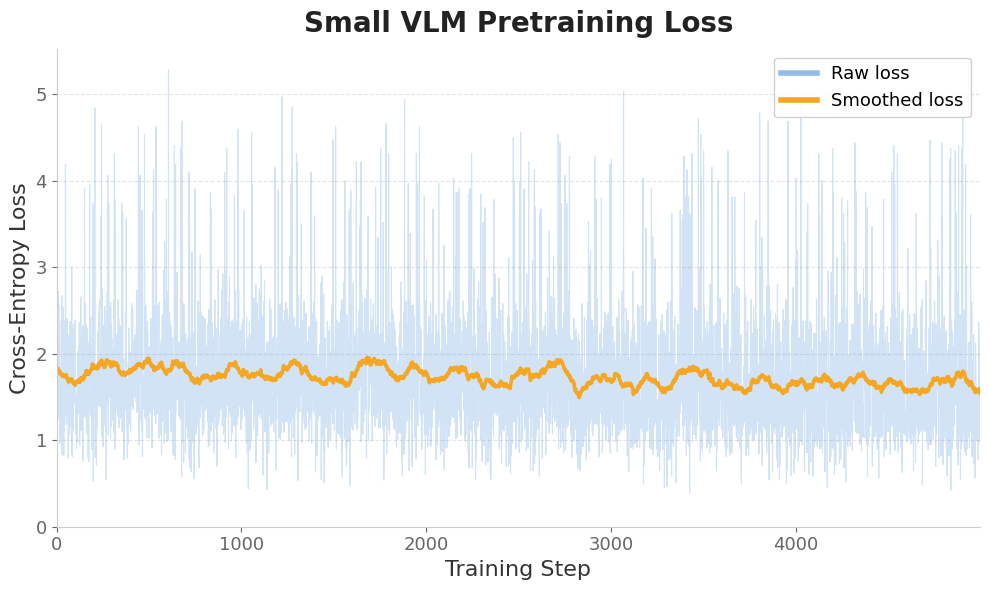

In [24]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --- Styling Configuration ---
FIGSIZE      = (10, 6)
TITLE_FS     = 20
LABEL_FS     = 16
TICK_FS      = 13
RAW_COLOR    = "#4A90D9"  # Soft blue for noisy step-by-step loss
SMOOTH_COLOR = "#F5A623"  # Orange for rolling mean trend line

JSON_FILE = 'chapter_3_loss.json'

# --- 1. Load Data with Fallback & Format Handling ---
if os.path.exists(JSON_FILE):
    with open(JSON_FILE, 'r') as f:
        raw_data = json.load(f)
else:
    # Synthetic fallback if training log is not yet available
    print(f"Warning: '{JSON_FILE}' not found. Generating sample training curve...")
    np.random.seed(42)
    steps = 5000
    base_loss = 8.0 * np.exp(-np.linspace(0, 3.5, steps)) + 1.5
    noise = np.random.normal(0, 0.25, steps)
    spikes = np.random.binomial(1, 0.005, steps) * np.random.uniform(0.5, 1.5, steps)
    raw_data = (base_loss + noise + spikes).clip(min=0.5).tolist()

# Parse into DataFrame based on data structure
if isinstance(raw_data, list):
    if len(raw_data) > 0 and isinstance(raw_data[0], dict):
        # Hugging Face Trainer log_history format
        df = pd.DataFrame(raw_data)
        loss_col = 'loss' if 'loss' in df.columns else 'train_loss'
        df = df.dropna(subset=[loss_col]).rename(columns={loss_col: 'Loss'})
        df['Step'] = df['step'] if 'step' in df.columns else df.index
    else:
        # Standard list of loss floats
        df = pd.DataFrame({'Loss': raw_data})
        df['Step'] = df.index
elif isinstance(raw_data, dict):
    loss_key = 'loss' if 'loss' in raw_data else ('train_loss' if 'train_loss' in raw_data else list(raw_data.keys())[0])
    df = pd.DataFrame({'Loss': raw_data[loss_key]})
    df['Step'] = raw_data.get('step', df.index)

# --- 2. Calculate Rolling Smoothed Curve ---
window_size = max(10, int(len(df) * 0.02))
df['Smoothed'] = df['Loss'].rolling(window=window_size, min_periods=1, center=True).mean()

# --- 3. Plotting ---
fig, ax = plt.subplots(figsize=FIGSIZE)

# Raw noisy loss (semi-transparent) & smoothed rolling trend line
ax.plot(df['Step'], df['Loss'],     color=RAW_COLOR,    alpha=0.25, linewidth=0.8)
ax.plot(df['Step'], df['Smoothed'], color=SMOOTH_COLOR, linewidth=2.5)

# Axis & Title formatting
ax.set_title('Small VLM Pretraining Loss', fontsize=TITLE_FS, pad=12, fontweight='bold', color='#222222')
ax.set_xlabel('Training Step', fontsize=LABEL_FS, color='#333333')
ax.set_ylabel('Cross-Entropy Loss', fontsize=LABEL_FS, color='#333333')
ax.tick_params(labelsize=TICK_FS, colors='#666666')
ax.set_xlim(0, len(df) - 1)
ax.set_ylim(bottom=0)

# Minimalist Spines & Grid
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cccccc')
ax.spines['bottom'].set_color('#cccccc')
ax.grid(axis='y', linestyle='--', alpha=0.5, color='#cccccc')

# Legend with thickened handles
legend_handles = [
    Line2D([0], [0], color=RAW_COLOR,    linewidth=4, alpha=0.6, label='Raw loss'),
    Line2D([0], [0], color=SMOOTH_COLOR, linewidth=4,            label='Smoothed loss'),
]
ax.legend(handles=legend_handles, fontsize=TICK_FS, framealpha=0.9, edgecolor='#cccccc', loc='upper right')

plt.tight_layout()
plt.savefig('vlm_training_loss.png', dpi=300, bbox_inches='tight')
plt.show()